In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_ollama import ChatOllama 
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [3]:
llm= ChatOllama(
    model="llama3.2:1b",
    temperature=0
)

In [4]:
class JokeState(TypedDict):

    topic: str
    joke: str
    explanation: str

In [5]:
def generate_joke(state: JokeState):

    prompt = f'generate a joke on the topic {state["topic"]}'
    response = llm.invoke(prompt).content

    return {'joke': response}

In [6]:
def generate_explanation(state: JokeState):

    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = llm.invoke(prompt).content

    return {'explanation': response}

In [7]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

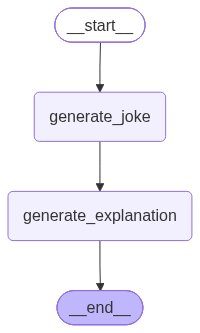

In [11]:
graph.compile()

In [8]:
config1 = {"configurable": {"thread_id": "1"}}
workflow.invoke({'topic':'pizza'}, config=config1)

{'topic': 'pizza',
 'joke': 'Why did the pizza go to therapy?',
 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to address mental health issues or problems.\n* In a more idiomatic sense, "therapy" can also mean "to treat" or "to make something better," as in "I\'m going to therapy to work through my issues."\n\nSo, the joke is saying that the pizza went to therapy because it was having problems, but also because it was literally being treated (as in, being cooked and delivered) and was seeking to improve its condition. It\'s a lighthearted and humorous way to poke fun at the idea of a pizza needing therapy, rather than a serious mental health issue.'}

In [12]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza go to therapy?', 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to address mental health issues or problems.\n* In a more idiomatic sense, "therapy" can also mean "to treat" or "to make something better," as in "I\'m going to therapy to work through my issues."\n\nSo, the joke is saying that the pizza went to therapy because it was having problems, but also because it was literally being treated (as in, being cooked and delivered) and was seeking to improve its condition. It\'s a lighthearted and humorous way to poke fun at the idea of a pizza needing therapy, rather than a serious mental health issue.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcbeb-0478-6523-8002-bcde837cf911

In [18]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza go to therapy?', 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to address mental health issues or problems.\n* In a more idiomatic sense, "therapy" can also mean "to treat" or "to make something better," as in "I\'m going to therapy to work through my issues."\n\nSo, the joke is saying that the pizza went to therapy because it was having problems, but also because it was literally being treated (as in, being cooked and delivered) and was seeking to improve its condition. It\'s a lighthearted and humorous way to poke fun at the idea of a pizza needing therapy, rather than a serious mental health issue.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcbeb-0478-6523-8002-bcde837cf91

In [20]:
config2 = {"configurable": {"thread_id": "2"}}
workflow.invoke({'topic':'pasta'}, config=config2)

{'topic': 'pasta',
 'joke': 'Why did the pasta go to therapy?',
 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to help individuals overcome mental or emotional issues.\n* In a culinary sense, pasta is a type of food that is often served with sauces and is a common ingredient in many dishes.\n\nThe joke is funny because it takes the two meanings of "therapy" and combines them in a way that is unexpected and clever. The punchline "Why did the pasta go to therapy?" is a clever play on words, implying that the pasta is seeking help to overcome its own "dough" (a common pasta ingredient) or perhaps to work through its own "meat" (a common pasta topping). The humor comes from the unexpected twist on the usual meaning of the word "therapy".'}

In [21]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the pasta go to therapy?', 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to help individuals overcome mental or emotional issues.\n* In a culinary sense, pasta is a type of food that is often served with sauces and is a common ingredient in many dishes.\n\nThe joke is funny because it takes the two meanings of "therapy" and combines them in a way that is unexpected and clever. The punchline "Why did the pasta go to therapy?" is a clever play on words, implying that the pasta is seeking help to overcome its own "dough" (a common pasta ingredient) or perhaps to work through its own "meat" (a common pasta topping). The humor comes from the unexpected twist on the usual meaning of the word "therapy".'}, next=(), config={'configurable': {'threa

In [22]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the pasta go to therapy?', 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to help individuals overcome mental or emotional issues.\n* In a culinary sense, pasta is a type of food that is often served with sauces and is a common ingredient in many dishes.\n\nThe joke is funny because it takes the two meanings of "therapy" and combines them in a way that is unexpected and clever. The punchline "Why did the pasta go to therapy?" is a clever play on words, implying that the pasta is seeking help to overcome its own "dough" (a common pasta ingredient) or perhaps to work through its own "meat" (a common pasta topping). The humor comes from the unexpected twist on the usual meaning of the word "therapy".'}, next=(), config={'configurable': {'thre

### Time Travel

In [23]:
workflow.get_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f1dcbea-752c-6e80-8000-5d08a3bd8af4"}})

StateSnapshot(values={'topic': 'pizza'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_id': '1f1dcbea-752c-6e80-8000-5d08a3bd8af4'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-10T04:24:43.431488+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcbea-7525-696d-bfff-7bd574aea3fd'}}, tasks=(PregelTask(id='491b55ae-5fc3-cfa9-bd3a-df34fc736c21', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why did the pizza go to therapy?'}),), interrupts=())

In [24]:
workflow.invoke(None, {"configurable": {"thread_id": "1", "checkpoint_id": "1f1dcbea-752c-6e80-8000-5d08a3bd8af4"}})

{'topic': 'pizza',
 'joke': 'Why did the pizza go to therapy?',
 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to address mental health issues or problems.\n* In a more idiomatic sense, "therapy" can also mean "to treat" or "to make something better," as in "I\'m going to therapy to work through my issues."\n\nSo, the joke is saying that the pizza went to therapy because it was having problems, but also because it was literally being treated (as in, being cooked and delivered) and was seeking to improve its condition. It\'s a lighthearted and humorous way to poke fun at the idea of a pizza needing therapy, rather than a serious mental health issue.'}

In [25]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza go to therapy?', 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to address mental health issues or problems.\n* In a more idiomatic sense, "therapy" can also mean "to treat" or "to make something better," as in "I\'m going to therapy to work through my issues."\n\nSo, the joke is saying that the pizza went to therapy because it was having problems, but also because it was literally being treated (as in, being cooked and delivered) and was seeking to improve its condition. It\'s a lighthearted and humorous way to poke fun at the idea of a pizza needing therapy, rather than a serious mental health issue.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcc61-6a57-661c-8003-c03d7f6c03b

#### Updating State

In [26]:
workflow.update_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f1dcbea-752c-6e80-8000-5d08a3bd8af4", "checkpoint_ns": ""}}, {'topic':'samosa'})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1dcc66-e105-6334-8001-1bd86c9e771d'}}

In [27]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcc66-e105-6334-8001-1bd86c9e771d'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-10T05:20:23.339499+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcbea-752c-6e80-8000-5d08a3bd8af4'}}, tasks=(PregelTask(id='2c65f5e0-7289-f2c7-4b1b-39cba28e33bd', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza go to therapy?', 'explanation': 'The joke is a play on words, using the multiple meanings of the phrase "therapy" to create a pun.\n\nIn this case, "therapy" has a double meaning:\n\n* In a literal sense, therapy refers to a treatment or counseling session to address mental health issues or problems.\n* In a mo

In [28]:
workflow.invoke(None, {"configurable": {"thread_id": "1", "checkpoint_id": "1f1dcc66-e105-6334-8001-1bd86c9e771d"}})

{'topic': 'samosa',
 'joke': 'Why did the samosa go to therapy?\n\nBecause it was feeling a little "folded" under the pressure.',
 'explanation': 'That\'s a clever play on words. The joke is funny because it takes the common phrase "feeling folded under the pressure" (meaning feeling overwhelmed or stressed) and applies it to a samosa, a type of Indian pastry. The word "folded" has a double meaning here, referring both to the samosa\'s shape and its emotional state. It\'s a lighthearted and humorous way to poke fun at the samosa\'s situation, making it a clever and amusing joke.'}

In [29]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa go to therapy?\n\nBecause it was feeling a little "folded" under the pressure.', 'explanation': 'That\'s a clever play on words. The joke is funny because it takes the common phrase "feeling folded under the pressure" (meaning feeling overwhelmed or stressed) and applies it to a samosa, a type of Indian pastry. The word "folded" has a double meaning here, referring both to the samosa\'s shape and its emotional state. It\'s a lighthearted and humorous way to poke fun at the samosa\'s situation, making it a clever and amusing joke.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcc6f-1848-618b-8003-fe2bef8622a5'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-11-10T05:24:03.882433+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcc6e-d9d5-623b-8002-44b7cec3e695'}}, tasks=(), interrupts=()),
 

### Fault Tolerance

In [2]:
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import InMemorySaver
from typing import TypedDict
import time

In [3]:
# 1. Define the state
class CrashState(TypedDict):
    input: str
    step1: str
    step2: str

In [4]:
# 2. Define steps
def step_1(state: CrashState) -> CrashState:
    print("✅ Step 1 executed")
    return {"step1": "done", "input": state["input"]}

def step_2(state: CrashState) -> CrashState:
    print("⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)")
    time.sleep(1000)  # Simulate long-running hang
    return {"step2": "done"}

def step_3(state: CrashState) -> CrashState:
    print("✅ Step 3 executed")
    return {"done": True}

In [5]:
# 3. Build the graph
builder = StateGraph(CrashState)
builder.add_node("step_1", step_1)
builder.add_node("step_2", step_2)
builder.add_node("step_3", step_3)

builder.set_entry_point("step_1")
builder.add_edge("step_1", "step_2")
builder.add_edge("step_2", "step_3")
builder.add_edge("step_3", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

In [ ]:
try:
    print("▶️ Running graph: Please manually interrupt during Step 2...")
    graph.invoke({"input": "start"}, config={"configurable": {"thread_id": 'thread-1'}})
except KeyboardInterrupt:
    print("❌ Kernel manually interrupted (crash simulated).")

▶️ Running graph: Please manually interrupt during Step 2...
✅ Step 1 executed
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)


In [ ]:
# 6. Re-run to show fault-tolerant resume
print("\n🔁 Re-running the graph to demonstrate fault tolerance...")
final_state = graph.invoke(None, config={"configurable": {"thread_id": 'thread-1'}})
print("\n✅ Final State:", final_state)

In [ ]:
list(graph.get_state_history({"configurable": {"thread_id": 'thread-1'}}))